# Epidemic Dynamics & Forecasting — LSTM (COVID-19, India)

This notebook trains an LSTM on OWID COVID-19 data for India. It follows the time split used in the Epidemic Dynamics project:

- **Training data ends:** `2021-09-30`
- **Evaluation / forecast window ends:** `2022-03-31`
- **Target:** `new_cases_smoothed` (daily new COVID-19 cases, 7-day smoothed)
- **Forecast style:** rolling one-step-ahead predictions over the test period. Each prediction can use the previous observed values from the test period as they become available; this is not a fully recursive six-month forecast.

The data are downloaded from Our World in Data's public GitHub CSV. Since OWID can revise historical data, metrics may differ from earlier runs.

## 1. Imports and configuration

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

DATA_URL = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
COUNTRY = "India"
TARGET_COL = "new_cases_smoothed"

end_date = pd.Timestamp("2022-03-31")
train_end_date = pd.Timestamp("2021-09-30")
n_steps = 28  # use the previous 28 daily observations to predict the next day
EPOCHS = 100
BATCH_SIZE = 32

## 2. Load OWID data and select India

In [2]:
# OWID's complete CSV is large; this reads the published file directly.
owid = pd.read_csv(DATA_URL, usecols=["location", "date", "new_cases_smoothed", "new_cases"])

df = owid.loc[owid["location"].eq(COUNTRY)].copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.loc[df["date"].le(end_date)].sort_values("date")

# Use the same smoothed-case target commonly used in the project's ARIMA analysis.
# Fall back to the unsmoothed daily case count only where the smoothed value is missing.
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
df["new_cases"] = pd.to_numeric(df["new_cases"], errors="coerce")
df[TARGET_COL] = df[TARGET_COL].fillna(df["new_cases"])

df = df[["date", TARGET_COL]].dropna().drop_duplicates("date").sort_values("date").reset_index(drop=True)

# Keep the requested time range and make the daily index explicit.
start_date = df["date"].min()
daily_dates = pd.date_range(start=start_date, end=end_date, freq="D")
df = (df.set_index("date")
        .reindex(daily_dates)
        .rename_axis("date")
        .reset_index())

# Any remaining gaps are filled using time interpolation; edge gaps use nearest valid values.
df[TARGET_COL] = df[TARGET_COL].interpolate(method="linear").ffill().bfill()
df[TARGET_COL] = df[TARGET_COL].clip(lower=0)

print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Rows: {len(df):,}")
print(df.head())
print(df.tail())

Date range: 2020-01-05 to 2022-03-31
Rows: 817
        date  new_cases_smoothed
0 2020-01-05                 0.0
1 2020-01-06                 0.0
2 2020-01-07                 0.0
3 2020-01-08                 0.0
4 2020-01-09                 0.0
          date  new_cases_smoothed
812 2022-03-27             1658.86
813 2022-03-28             1658.86
814 2022-03-29             1658.86
815 2022-03-30             1658.86
816 2022-03-31             1658.86


## 3. Visualize the series and define the chronological split

Training rows: 635
Test rows: 182
Train end: 2021-09-30
Test start: 2021-10-01
Test end: 2022-03-31


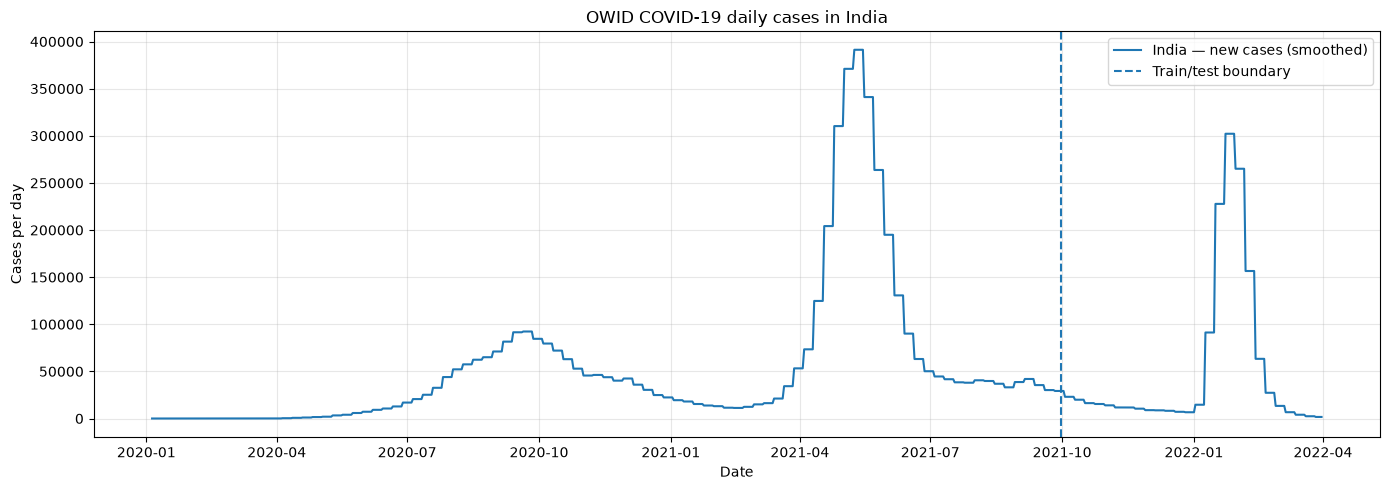

In [3]:
train_mask = df["date"] <= train_end_date
test_mask = (df["date"] > train_end_date) & (df["date"] <= end_date)

print("Training rows:", int(train_mask.sum()))
print("Test rows:", int(test_mask.sum()))
print("Train end:", df.loc[train_mask, "date"].max().date())
print("Test start:", df.loc[test_mask, "date"].min().date())
print("Test end:", df.loc[test_mask, "date"].max().date())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df["date"], df[TARGET_COL], linewidth=1.5, label="India — new cases (smoothed)")
ax.axvline(train_end_date, linestyle="--", label="Train/test boundary")
ax.set_title("OWID COVID-19 daily cases in India")
ax.set_xlabel("Date")
ax.set_ylabel("Cases per day")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Scale the target without leaking test data

The scaler is fitted **only on the training period**. We then transform the full series using that fitted scaler. Sequence targets are assigned by their target date, so test predictions are only scored when the target date is after `train_end_date`.

In [4]:
train_values = df.loc[train_mask, [TARGET_COL]].to_numpy(dtype=np.float32)
scaler = MinMaxScaler()
scaler.fit(train_values)

scaled_values = scaler.transform(df[[TARGET_COL]].to_numpy(dtype=np.float32)).astype(np.float32)

def create_sequences(values, dates, n_steps):
    X, y, target_dates = [], [], []
    for target_idx in range(n_steps, len(values)):
        X.append(values[target_idx - n_steps:target_idx, :])
        y.append(values[target_idx, 0])
        target_dates.append(dates.iloc[target_idx])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32), pd.to_datetime(target_dates)

X_all, y_all, target_dates = create_sequences(scaled_values, df["date"], n_steps)

train_seq_mask = target_dates <= train_end_date
test_seq_mask = (target_dates > train_end_date) & (target_dates <= end_date)

X_train, y_train = X_all[train_seq_mask], y_all[train_seq_mask]
X_test, y_test_scaled = X_all[test_seq_mask], y_all[test_seq_mask]
test_dates = target_dates[test_seq_mask]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Training target dates:", target_dates[train_seq_mask].min().date(), "to", target_dates[train_seq_mask].max().date())
print("Testing target dates:", test_dates.min().date(), "to", test_dates.max().date())

X_train shape: (607, 28, 1)
X_test shape: (182, 28, 1)
Training target dates: 2020-02-02 to 2021-09-30
Testing target dates: 2021-10-01 to 2022-03-31


## 5. Build and train the LSTM

In [5]:
model = Sequential([
    Input(shape=(n_steps, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

callbacks = [
    EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)
]

history = model.fit(
    X_train, y_train,
    validation_split=0.15,  # chronological tail of training sequences used for validation
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 28, 64)              │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 28, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.0336 - mae: 0.0999 - val_loss: 0.0051 - val_mae: 0.0707 - learning_rate: 0.0010
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0207 - mae: 0.1037 - val_loss: 8.8010e-04 - val_mae: 0.0274 - learning_rate: 0.0010
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0096 - mae: 0.0547 - val_loss: 2.5624e-04 - val_mae: 0.0110 - learning_rate: 0.0010
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0104 - mae: 0.0491 - val_loss: 8.9957e-04 - val_mae: 0.0283 - learning_rate: 0.0010
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0076 - mae: 0.0544 - val_loss: 1.2147e-04 - val_mae: 0.0091 - learning_rate: 0.0010
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0067 - mae: 0.0420 - val_loss: 8.1542e-04 - val_mae: 0.0274 - learning_rate: 0.0010
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0054 - mae: 0.0507 - val_loss: 2.7886e-04 - val_mae: 0.0149 - lear

## 6. Training history

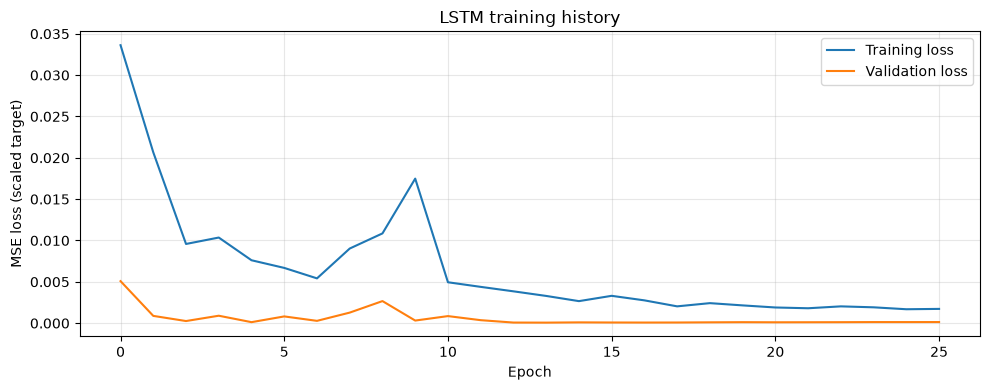

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.history["loss"], label="Training loss")
ax.plot(history.history["val_loss"], label="Validation loss")
ax.set_title("LSTM training history")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss (scaled target)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Predict the test period and calculate metrics

In [7]:
pred_scaled = model.predict(X_test, verbose=0)

y_pred = scaler.inverse_transform(pred_scaled).ravel()
y_test = scaler.inverse_transform(y_test_scaled.reshape(-1, 1)).ravel()

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

# MAPE is unstable when observed cases are zero or close to zero, so it is omitted.
print(f"Test RMSE: {rmse:,.2f} cases/day")
print(f"Test MAE:  {mae:,.2f} cases/day")

results = pd.DataFrame({
    "date": test_dates,
    "actual_cases": y_test,
    "lstm_predicted_cases": np.clip(y_pred, 0, None)
})
results.head()

Test RMSE: 36,858.31 cases/day
Test MAE:  18,890.62 cases/day


,date,actual_cases,lstm_predicted_cases
0,2021-10-01,29226.000000,29777.468750
1,2021-10-02,29226.000000,29603.205078
2,2021-10-03,23022.570312,29496.351562
3,2021-10-04,23022.570312,29219.423828
4,2021-10-05,23022.570312,28794.488281


## 8. Plot observed cases versus LSTM predictions

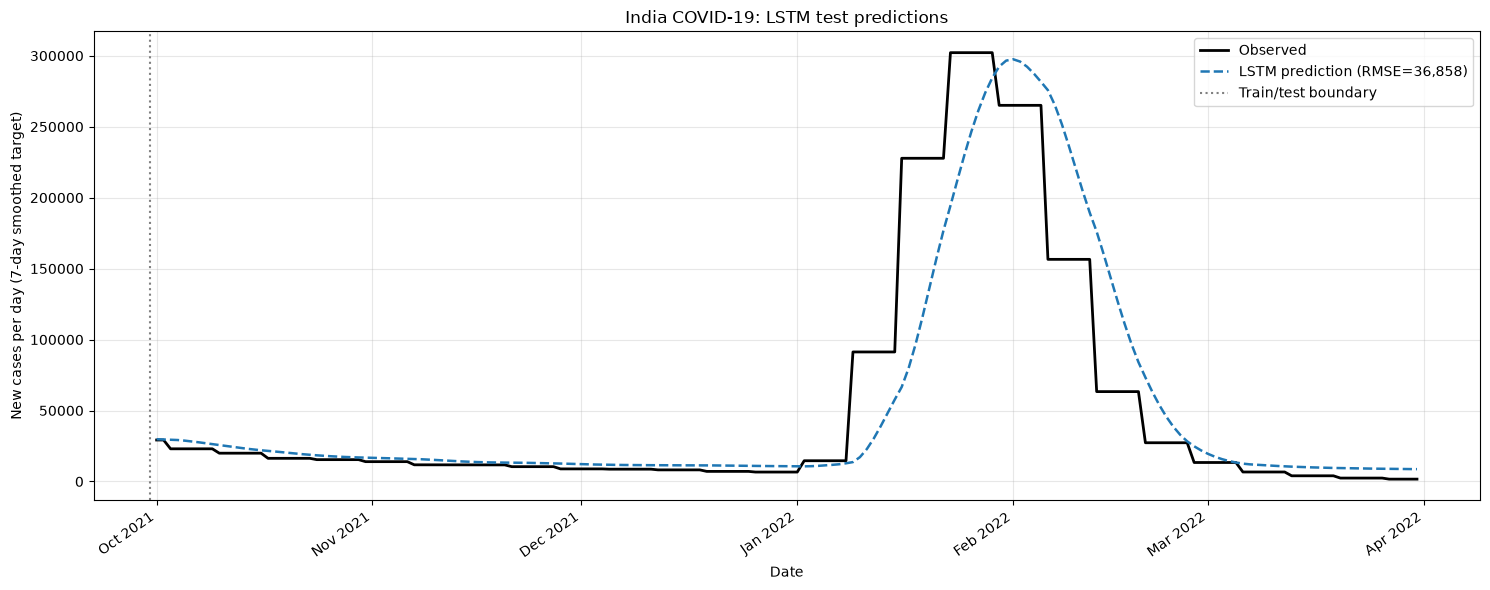

In [8]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(results["date"], results["actual_cases"], color="black", linewidth=2, label="Observed")
ax.plot(results["date"], results["lstm_predicted_cases"], linestyle="--", linewidth=1.8, label=f"LSTM prediction (RMSE={rmse:,.0f})")
ax.axvline(train_end_date, color="gray", linestyle=":", label="Train/test boundary")
ax.set_title("India COVID-19: LSTM test predictions")
ax.set_xlabel("Date")
ax.set_ylabel("New cases per day (7-day smoothed target)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 9. Inspect the predicted wave and residuals

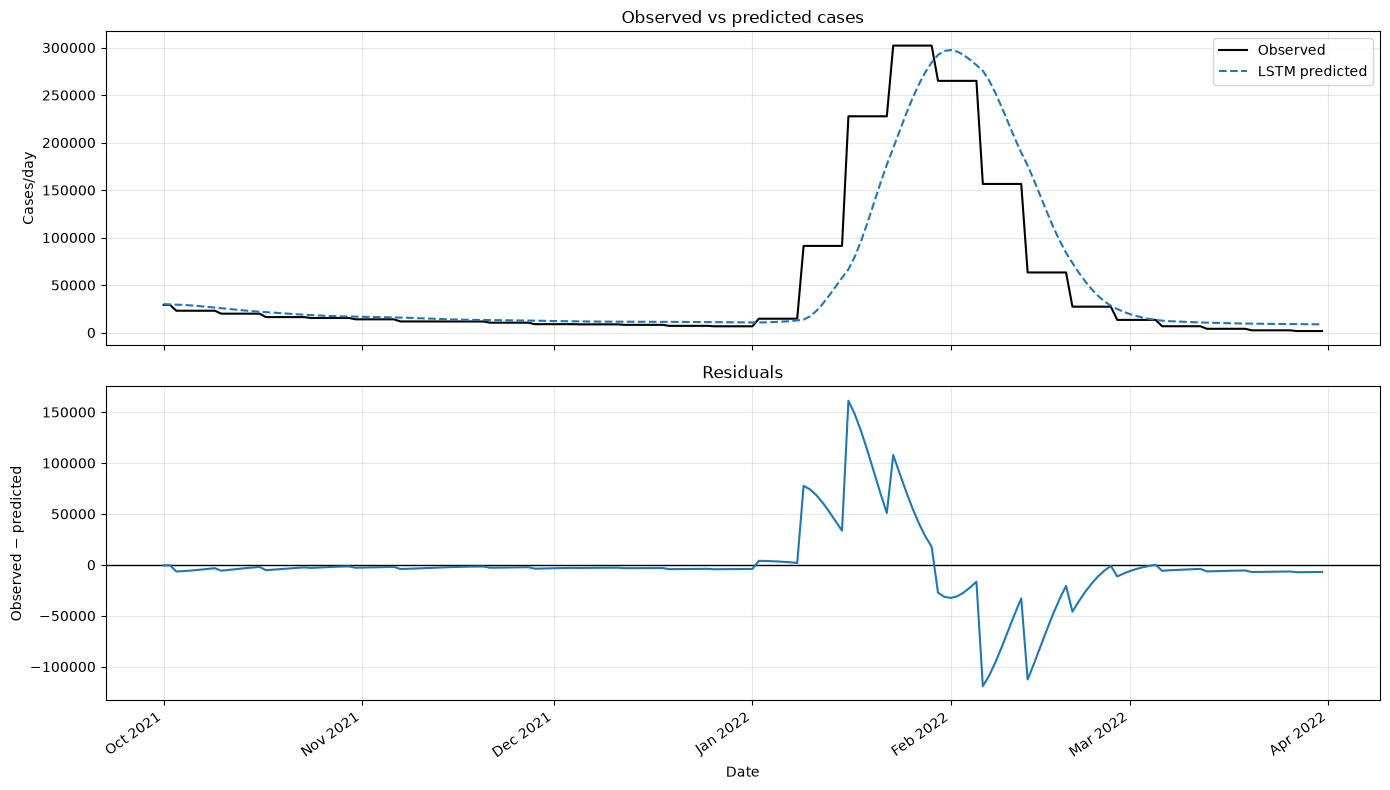

In [9]:
results["residual"] = results["actual_cases"] - results["lstm_predicted_cases"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(results["date"], results["actual_cases"], color="black", label="Observed")
ax1.plot(results["date"], results["lstm_predicted_cases"], linestyle="--", label="LSTM predicted")
ax1.set_ylabel("Cases/day")
ax1.set_title("Observed vs predicted cases")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.axhline(0, color="black", linewidth=1)
ax2.plot(results["date"], results["residual"])
ax2.set_ylabel("Observed − predicted")
ax2.set_xlabel("Date")
ax2.set_title("Residuals")
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax2.get_xticklabels(), rotation=35, ha="right")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Save predictions for comparison with SIR / ARIMA / XGBoost

The output CSV can be used to compare models on the same test dates. Make sure all models use the same target, dates, and metric definitions before comparing RMSE/MAE.

In [10]:
results.to_csv("india_covid_lstm_test_predictions.csv", index=False)
print("Saved: india_covid_lstm_test_predictions.csv")

Saved: india_covid_lstm_test_predictions.csv


## Interpretation and limitations

- This is a **univariate LSTM**: it uses past values of `new_cases_smoothed` only.
- The test results are **rolling one-step-ahead** predictions. For each test date, the input window includes the preceding observed cases, including observed test-period values. It therefore does not represent a forecast made once on 30 September 2021 for all six months ahead.
- COVID reporting and historical values can be revised. Negative or missing values and the fallback/interpolation steps can affect metrics.
- The model is not causal and should not be interpreted as a public-health decision tool.
- For a fair project comparison with SIR and ARIMA, use identical test dates and the same target (`new_cases_smoothed`) wherever possible.